# LeetCode #63: Unique Paths II

https://leetcode.com/problems/unique-paths-ii/

## Comparison of Approaches

| Approach | Time Complexity | Space Complexity | What that means in practice |
| :--- | :--- | :--- | :--- |
| **Brute Force: Try Every Path** | $O(2^{m+n})$ | $O(m+n)$ | From each square, try going right and try going down, and count the walks that reach the corner. A 100 × 100 grid has more paths than atoms in the universe. |
| **2D Table** | $O(m \times n)$ | $O(m \times n)$ | One box per square holding how many paths reach it, each filled once from the box above and the box to its left. At 100 × 100, 10,000 boxes. |
| **One Row, Reused** ★ | $O(m \times n)$ | $O(n)$ | The same sums, but only one row of 100 numbers is kept, updated in place as each new row is processed. |

$m$ is the number of rows and $n$ the number of columns. $O(m \times n)$ means the work grows with the number of squares: a 100 × 100 grid is 10,000 steps. $O(2^{m+n})$ means each extra row or column roughly doubles the work. $O(n)$ space means memory grows only with the width.

---

## Understanding the Methods

A robot starts in the top-left square and wants the bottom-right one, moving only **right** or **down**. Some squares hold an obstacle (`1`) and can't be entered. Count the different routes.

### Brute Force: Try Every Path
Recursively walk right and down from every square, stopping at obstacles and the grid's edge. The same squares are reached again and again along different routes, so the work explodes.

### 2D Table
Every path into a square arrives either from the square above or from the square to its left, never both. So `paths(r, c) = paths(r-1, c) + paths(r, c-1)`, and an obstacle square holds 0. Fill the table row by row; the answer is the bottom-right box.

### Optimal: One Row, Reused ★
To fill a row you only need the row above it and the box just filled to the left. Keep a single array `dp` the width of the grid. Before `dp[j]` is updated it still holds the row above's value; `dp[j-1]` already holds this row's left neighbour. So `dp[j] += dp[j-1]` is "above plus left", and an obstacle sets `dp[j] = 0`.

**Why this is better than the 2D table:** identical work and the same answer, with 100 numbers in memory instead of 10,000.

**Constraints:**
* `1 <= m, n <= 100`
* `obstacleGrid[i][j]` is `0` or `1`
* The answer is at most `2 * 10^9`

## Explain Like I'm a Newbie

### What the question is actually asking

A robot goes from the top-left square to the bottom-right one, only ever stepping right or down. Squares marked `1` are walls. How many different routes are there?

```
. . .        the wall in the middle leaves 2 routes:
. # .        along the top then down, or down the left then along the bottom
. . .
```

### The one idea you need: count arrivals, not routes

Don't trace routes. Ask, for each square, **how many routes reach it**. A route can only arrive from the square above or the square to the left, so that number is just *above + left*. A wall holds 0: nothing gets through it. Fill the grid row by row and the bottom-right square holds the answer.

The edges are where people slip. The top row has nothing above it, so each square there copies its left neighbour. That means one wall on the top row makes **every square to its right** 0, not just itself: the robot can't step back up to get round it. The left column works the same way going down.

### What that means in code

You only need the previous row, so the code keeps one array `dp`, one number per column. Walking along a row, `dp[j]` still holds the value from the row above until you overwrite it, and `dp[j-1]` already holds this row's left neighbour. So `dp[j] += dp[j-1]` is "above plus left", and a wall sets `dp[j] = 0`. This is **dynamic programming**: each answer is built from smaller ones already stored.

### Mistakes people make the first time

1. **Setting the top row and left column to 1 except on the walls themselves.** Both LeetCode samples pass. Then `[[0,0,1,0],[0,0,0,0],[1,0,0,0],[0,0,0,0]]` gives 14 instead of 12: the squares beyond each edge wall count routes that would have had to pass through it.
2. **Reusing #62's formula and subtracting the paths through each wall.** Also passes both samples, each with one wall. With two walls on the same diagonal, `[[0,0,0,0],[0,1,0,0],[0,0,1,0],[0,0,0,0]]`, the routes through both are subtracted twice and the answer comes out −4. The right answer is 4.
3. **Skipping a wall with `continue` instead of setting it to 0.** The row above's count stays in `dp[j]` and leaks into the squares after it.

### Things worth knowing

LeetCode promises the *answer* fits in 2 billion, not every square. A square cut off from the corner can hold a far bigger count; it never reaches the answer, but in a language that checks for overflow it can still stop the program.

## Talking It Through in an Interview

*Written from the interviewer's chair. This is what I'd want to hear from you, from the moment I show you the problem to the moment the code is on the board.*

---

### The thirty-second version

Where you should end up: *"Every route into a square comes from above or from the left, so the number of routes to it is the sum of those two, and an obstacle holds zero. I fill that row by row. I only ever need the row above, so I keep one array the width of the grid: before I touch `dp[j]` it's the value from above, and `dp[j-1]` is already this row's left neighbour, so `dp[j] += dp[j-1]`. Obstacles set it to zero. That's $O(m \times n)$ time and $O(n)$ memory."*

And then, unprompted: *"the edges are where this goes wrong. One obstacle on the top row zeroes everything to its right, and the one-array version gets that for free."*

---

### I slide the problem across the table

> **You:** "So it's #62 with walls. Right and down only, start top-left, finish bottom-right, and a `1` can't be stepped on. What if the start or the finish is a `1`?"

**"Then there are no routes, and the answer is 0."** That's the clarifier I want. It's the first edge case the problem hides, and you found it by thinking about the actual grid.

> **You:** "And the answer fits in a 32-bit integer?"

**"LeetCode guarantees at most two billion."** Good question, and I'll come back to the word *answer* in it at the end.

What I don't need is "can the grid be empty?" It's at least 1 × 1, and the constraints say so.

---

### Now tell me what's actually hard about it

If you open with "it's DP", I'll ask what the subproblem is. I want the difficulty first:

> **You:** "Counting routes directly blows up: every square branches two ways, so a big grid has an astronomical number of routes. But two routes that reach the same square have the same futures. So I should count how many routes *arrive* at each square, once, instead of following each route."

> **You:** "And a route only arrives from above or from the left. So arrivals at a square are arrivals above plus arrivals left, and an obstacle has none. Those two cases never overlap, so I can just add."

That's exactly the order I'm looking for. Then the part most people skip:

> **You:** "The first row and column look like base cases, all ones, but they aren't, not with obstacles. One obstacle on the top row means everything right of it is unreachable, because you can't go back up."

If you'd written "first row is all ones unless the square itself is an obstacle", both samples would still pass, and I'd ask about `[[0,1,0]]`.

---

### Before you touch the board, tell me the shape and the cost

> **You:** "Two loops, rows then columns, constant work per square: $m \times n$ steps, 10,000 at the limit. A full table is 10,000 numbers. But each row only reads the row above, so I'll keep one row: 100 numbers."

If you start with the 2D table, that's fine. I'll ask whether you need all of it, and the answer I want is "only the previous row, and with the right update order not even a second array."

---

### Now whiteboard it

```
m, n = len(grid), len(grid[0])
dp = [0] * n
dp[0] = 0 if grid[0][0] == 1 else 1
```

> **You:** "`dp[0]` is one route to the start, unless the start is blocked. Everything else starts at zero, which is right for an imaginary row above the grid: nothing comes from up there."

That second sentence is what makes the top row work without a special case.

```
for i in range(m):
    for j in range(n):
        if grid[i][j] == 1:
            dp[j] = 0
        elif j > 0:
            dp[j] += dp[j - 1]
return dp[-1]
```

> **You:** "Before this line runs, `dp[j]` is the count for the square above. `dp[j-1]` was updated a moment ago, so it's the square to the left in this row. Adding them is above plus left. For `j = 0` there's no left, so it just keeps the value from above."

That's the line I'll press on. If you don't explain why one array is enough, I'll ask what `dp[j]` means halfway through a row. The answer is "left of `j` it's this row, from `j` on it's still the row above".

> **You:** "And an obstacle sets zero rather than being skipped. Skip it and the count from above stays there and flows into the next square."

---

### Walk me through it before you say you're done

> **You:** "The sample with the obstacle in the middle. Row 0: `[1, 1, 1]`. Row 1: `dp[0]` stays 1, the obstacle makes `dp[1]` 0, `dp[2]` is 1 above plus 0 left, 1. Row 2: `dp[0]` 1, `dp[1]` is 0 plus 1, 1, `dp[2]` is 1 plus 1, 2. Answer 2."

Then the clarifier from the start:

> **You:** "Blocked start: `dp[0]` begins at 0 and the loop sets it to 0 again, so nothing ever becomes positive. The answer's 0 with no special case. Blocked finish: the last square is set to 0 on the last step, same answer."

That's the dry run I want: one ordinary run, then the edge we agreed on at the start.

---

### Then tell me where it breaks, before I ask

It's optimal for time, so this is about the assumption the integers lean on:

> **You:** "The guarantee is about the answer, not every square. A big open region that's walled off from the corner can count far more than two billion routes. That count never reaches the corner, because anything it feeds can't reach the corner either. In C# or Go it wraps around harmlessly, but Rust checks for overflow in debug builds and would panic on a valid input. If that mattered, I'd use 64-bit counts or cap them."

> **You:** "And if the robot could also move up or left, this falls apart: routes could loop, 'above plus left' isn't the whole story, and it becomes a graph search problem."

That's a candidate who read the guarantee carefully and knows exactly which property makes the DP valid.

---

### What would worry me

- **First row and column hard-coded to 1**, ignoring obstacles beyond the first one.
- **Subtracting paths through each obstacle from #62's formula**, which double-counts as soon as two obstacles share a route.
- **A 2D table** with no answer to "do you need all of it?"
- **`continue` on an obstacle** instead of zeroing it.

## Solutions

### C#

In [ ]:
public class Solution {
    public int UniquePathsWithObstacles(int[][] obstacleGrid) {
        int m = obstacleGrid.Length, n = obstacleGrid[0].Length;

        // One row, reused: dp[j] = routes reaching column j of the current row.
        // Zeros everywhere = an imaginary row above the grid that nothing comes from
        int[] dp = new int[n];

        // One route to the start square, unless it's an obstacle
        dp[0] = obstacleGrid[0][0] == 1 ? 0 : 1;

        for (int i = 0; i < m; i++) {
            for (int j = 0; j < n; j++) {
                if (obstacleGrid[i][j] == 1) {
                    // Nothing gets through. Set 0, don't skip: skipping would
                    // leave the row above's count here to leak rightward
                    dp[j] = 0;
                } else if (j > 0) {
                    // dp[j] still holds the square ABOVE; dp[j-1] was just
                    // updated, so it's the square to the LEFT. Above + left.
                    // (j == 0: no left, keep the value from above. This also
                    // carries an edge obstacle's 0 down the left column)
                    dp[j] += dp[j - 1];
                }
            }
        }

        return dp[n - 1];
    }
}

### Python

In [ ]:
class Solution:
    def uniquePathsWithObstacles(self, obstacle_grid: list[list[int]]) -> int:
        m, n = len(obstacle_grid), len(obstacle_grid[0])

        # One row, reused: dp[j] = routes reaching column j of the current row.
        # Zeros everywhere = an imaginary row above the grid that nothing comes from
        dp = [0] * n

        # One route to the start square, unless it's an obstacle
        dp[0] = 0 if obstacle_grid[0][0] == 1 else 1

        for i in range(m):
            for j in range(n):
                if obstacle_grid[i][j] == 1:
                    # Nothing gets through. Set 0, don't skip: skipping would
                    # leave the row above's count here to leak rightward
                    dp[j] = 0
                elif j > 0:
                    # dp[j] still holds the square ABOVE; dp[j-1] was just
                    # updated, so it's the square to the LEFT. Above + left.
                    # (j == 0: no left, keep the value from above. This also
                    # carries an edge obstacle's 0 down the left column)
                    dp[j] += dp[j - 1]

        return dp[-1]

### Go

In [ ]:
func uniquePathsWithObstacles(obstacleGrid [][]int) int {
    m, n := len(obstacleGrid), len(obstacleGrid[0])

    // One row, reused: dp[j] = routes reaching column j of the current row.
    // Zeros everywhere = an imaginary row above the grid that nothing comes from
    dp := make([]int, n)

    // One route to the start square, unless it's an obstacle
    if obstacleGrid[0][0] == 0 {
        dp[0] = 1
    }

    for i := 0; i < m; i++ {
        for j := 0; j < n; j++ {
            if obstacleGrid[i][j] == 1 {
                // Nothing gets through. Set 0, don't skip: skipping would
                // leave the row above's count here to leak rightward
                dp[j] = 0
            } else if j > 0 {
                // dp[j] still holds the square ABOVE; dp[j-1] was just
                // updated, so it's the square to the LEFT. Above + left.
                // (j == 0: no left, keep the value from above. This also
                // carries an edge obstacle's 0 down the left column)
                dp[j] += dp[j-1]
            }
        }
    }

    return dp[n-1]
}

### Rust

`dp` holds `i32`s. LeetCode guarantees the *answer* fits, but a square walled off from the corner can count more than $2^{31}$ routes; Rust checks `+=` for overflow in debug builds and would panic there, where C# and Go wrap silently. The wrapped value can never reach the corner, so their answers stay right.

In [ ]:
impl Solution {
    pub fn unique_paths_with_obstacles(obstacle_grid: Vec<Vec<i32>>) -> i32 {
        let m = obstacle_grid.len();
        let n = obstacle_grid[0].len();

        // One row, reused: dp[j] = routes reaching column j of the current row.
        // Zeros everywhere = an imaginary row above the grid that nothing comes from
        let mut dp = vec![0i32; n];

        // One route to the start square, unless it's an obstacle
        dp[0] = if obstacle_grid[0][0] == 1 { 0 } else { 1 };

        for i in 0..m {
            for j in 0..n {
                if obstacle_grid[i][j] == 1 {
                    // Nothing gets through. Set 0, don't skip: skipping would
                    // leave the row above's count here to leak rightward
                    dp[j] = 0;
                } else if j > 0 {
                    // dp[j] still holds the square ABOVE; dp[j-1] was just
                    // updated, so it's the square to the LEFT. Above + left.
                    // (j == 0: no left, keep the value from above. This also
                    // carries an edge obstacle's 0 down the left column)
                    dp[j] += dp[j - 1];
                }
            }
        }

        dp[n - 1]
    }
}

## Example Scenarios

### 1. Common Case — One Obstacle in the Middle
**Input:** `obstacleGrid = [[0,0,0],[0,1,0],[0,0,0]]`

Row 0 is all 1s. In row 1 the obstacle sets its square to 0, so the right-hand square gets only its 1 from above. Row 2 adds up to 1, then 1, then 2: along the top and down, or down the left and along. **Output:** `2`

### 2. Slightly Complex — Obstacle on the Top Edge
**Input:** `obstacleGrid = [[0,1],[0,0]]`

The obstacle zeroes the top-right square, and nothing can get round it from above. The bottom-right square gets 0 from above plus 1 from the left. **Output:** `1`

### 3. Edge Case: Time Factor — The Largest Grid
**Input:** `obstacleGrid` is 100 × 100, all `0` except row 1, which is all `1` apart from its last square

All 10,000 squares are visited, each once, which is the most work any input can cause. The wall forces every route along the top row, through the one gap at the right, and straight down. **Output:** `1`

### 4. Edge Case: Space Factor — A Single Column
**Input:** `obstacleGrid = [[0],[0],[0]]`

The reused row is as long as the grid is wide, here one number; for a 100-wide grid it would be 100, never the 10,000 a full table would hold. The only route is straight down. **Output:** `1`

### 5. Almost-Impossible but Plausible — The Start Is Blocked
**Input:** `obstacleGrid = [[1,0],[0,0]]`

`dp[0]` starts at 0 and the loop sets it to 0 again, so no square ever gets a route. No special case is needed: the zeros do it. **Output:** `0`

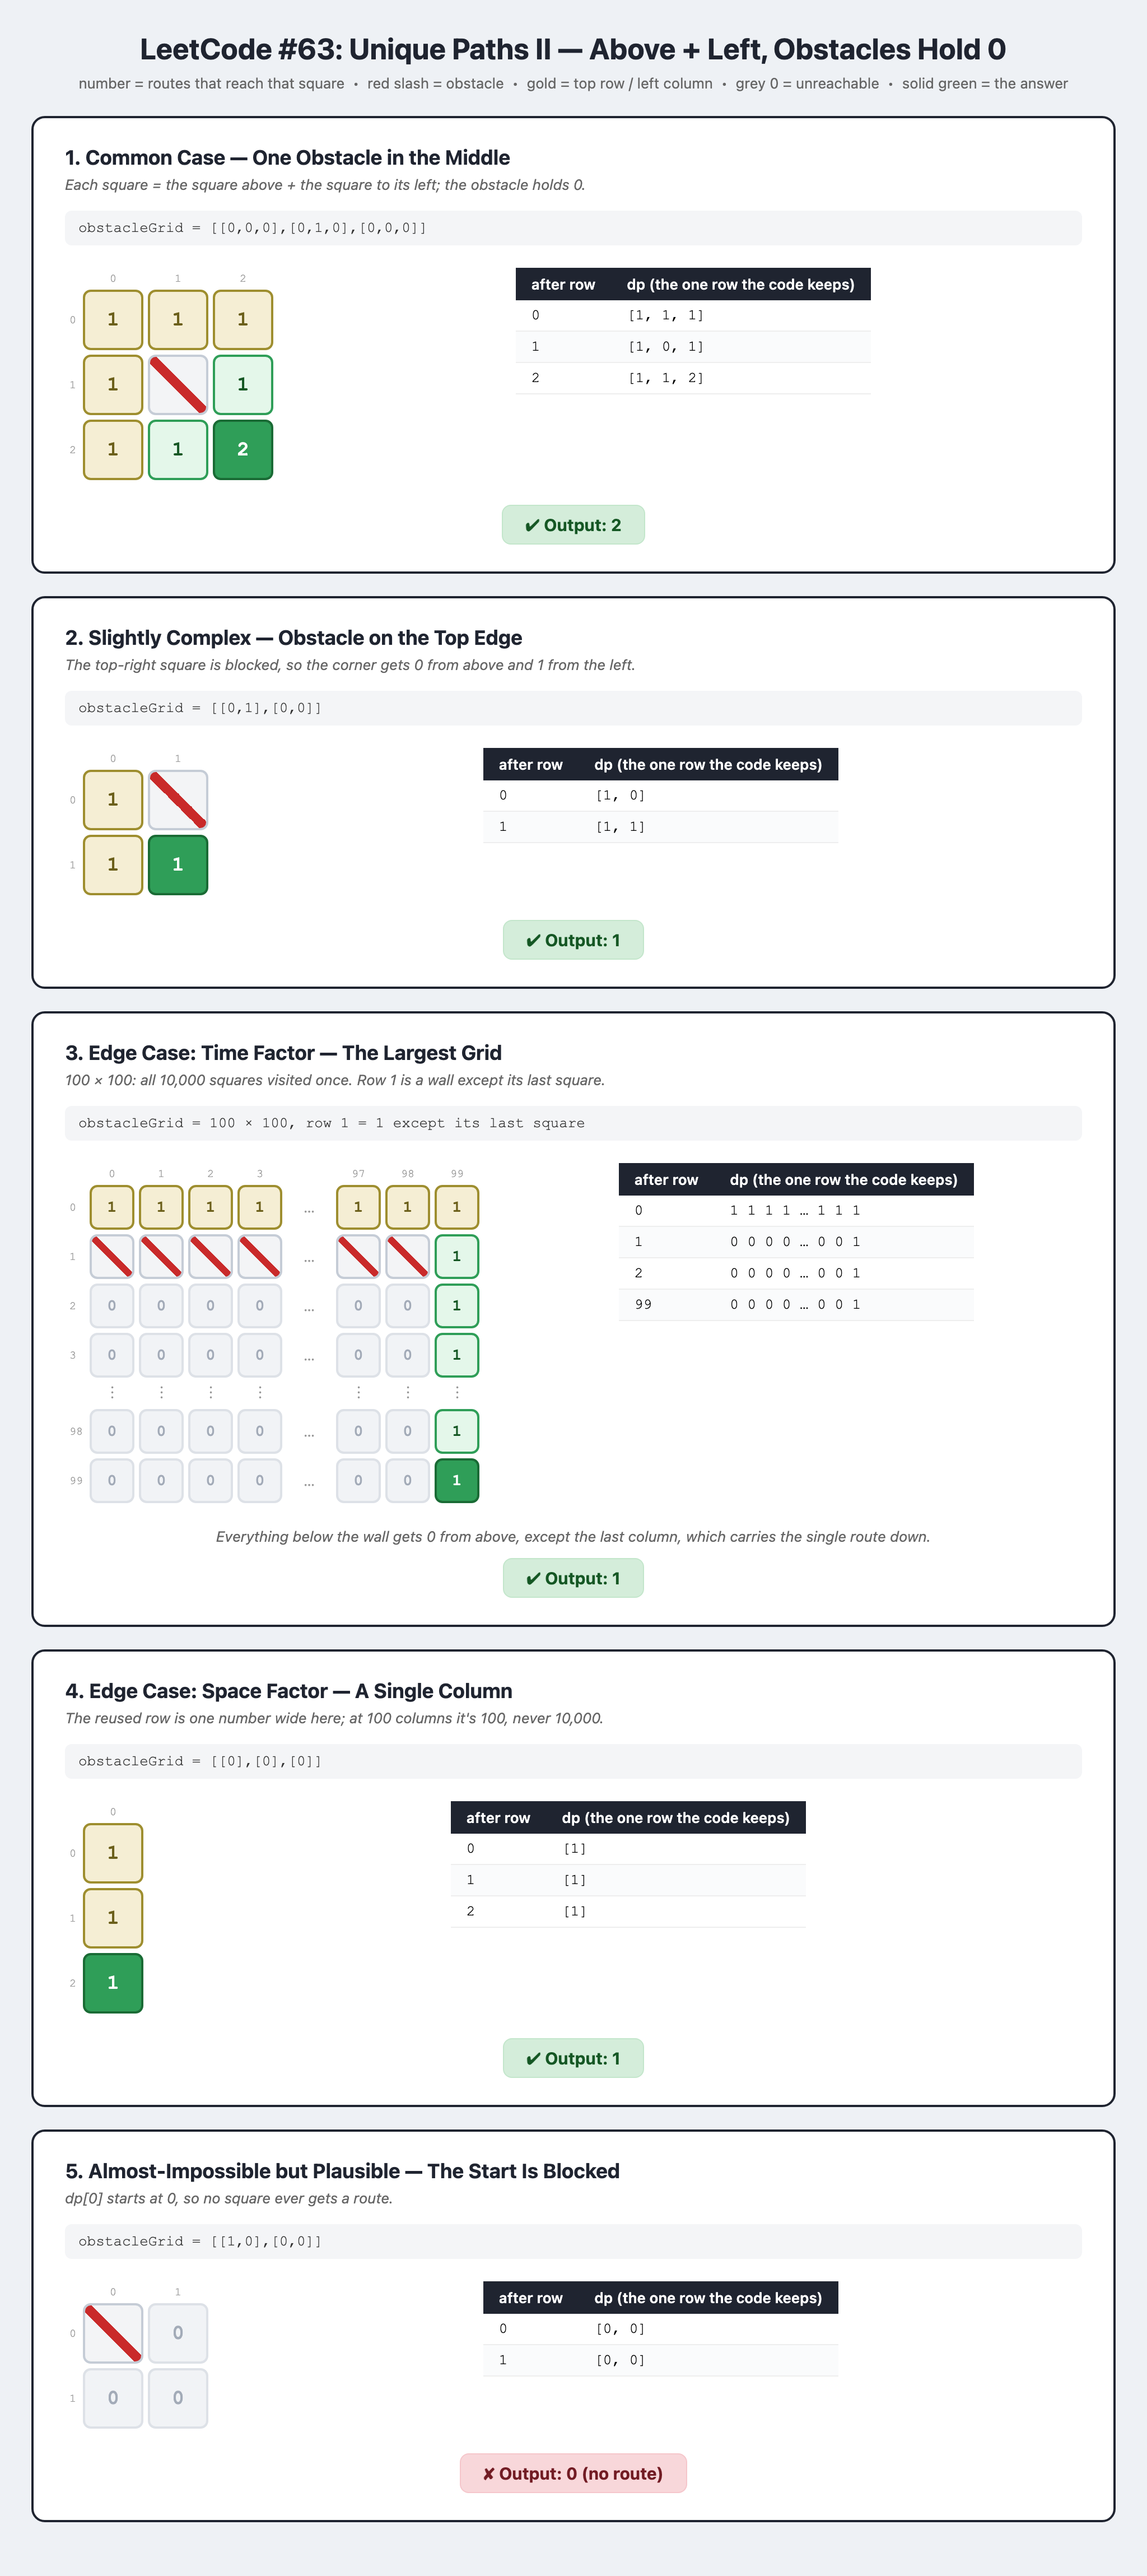

## Watch It Run

*Watch (1,2): its 1 comes only from above, because the obstacle to its left holds 0, and that 0 is why the corner ends up with 2.*

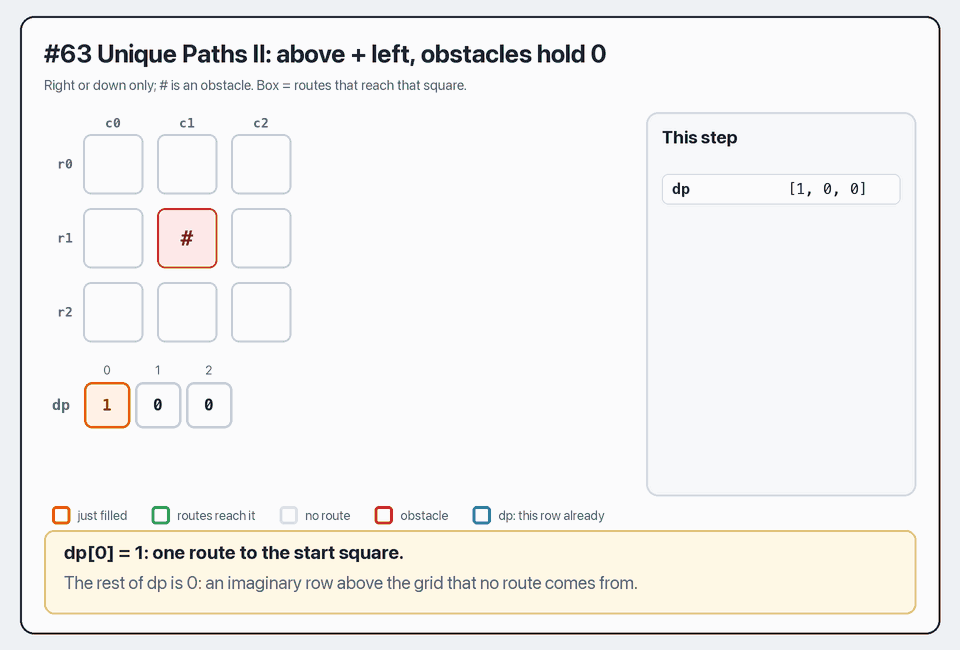

**[Step through it yourself: play, pause, scrub and step through this walkthrough, plus a harder example](https://sanjay-bhat.github.io/ProgrammingConcepts/walkthroughs/0063.html)**